In [2]:
import ipywidgets as widgets
from IPython.display import display

In [3]:
# Create a button widget
button = widgets.Button(
    description='Click Me!',
    button_style='success',  # Options: 'success', 'info', 'warning', 'danger'
    icon='check',
)


# Define what happens when the button is clicked
def on_button_clicked(b):
  print('Button was clicked! Running your code...')
  # Put your code or function call here!
  # Example: print("Hello World")


# Connect the button to the function
button.on_click(on_button_clicked)

# Display the button in the notebook
display(button)

Button(button_style='success', description='Click Me!', icon='check', style=ButtonStyle())

Epoch 1/30


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.5667 - loss: 0.9225 - val_accuracy: 0.6333 - val_loss: 0.9029
Epoch 2/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6667 - loss: 0.8711 - val_accuracy: 0.6000 - val_loss: 0.8569
Epoch 3/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6000 - loss: 0.8366 - val_accuracy: 0.5333 - val_loss: 0.8346
Epoch 4/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.5000 - loss: 0.8230 - val_accuracy: 0.5333 - val_loss: 0.8200
Epoch 5/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5500 - loss: 0.8082 - val_accuracy: 0.5667 - val_loss: 0.8073
Epoch 6/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6167 - loss: 0.7951 - val_accuracy: 0.6000 - val_loss: 0.7965
Epoch 7/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6333 - loss: 0.7833 - val_accuracy: 0.6000 - val_loss: 0.7836
Epoch 8/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6250 - loss: 0.7715 - val_accuracy: 0.6000 - val_loss: 0.7724
Ep

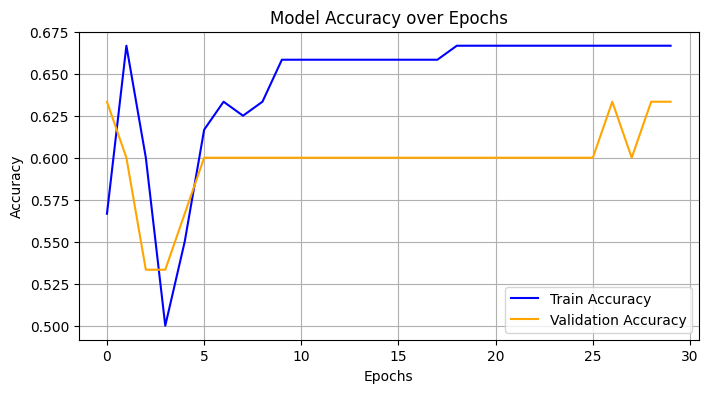

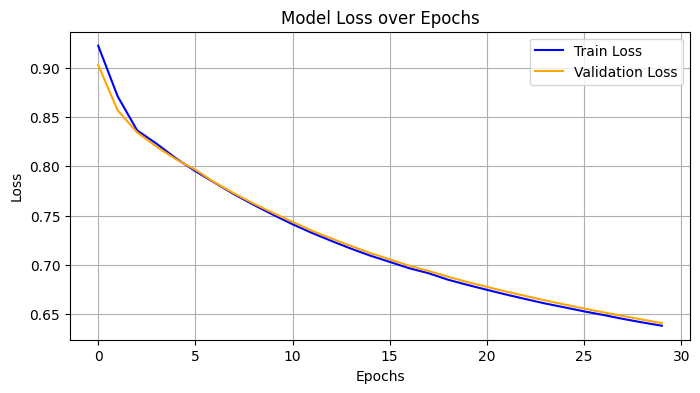

In [4]:
# ==========================================
# Complete Neural Network Pipeline (Iris Dataset)
# ==========================================

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from tensorflow.keras.layers import Dense
from tensorflow.keras.models import Sequential

# 1. Load dataset (Iris dataset)
iris = load_iris()
X = iris.data
y = iris.target.reshape(-1, 1)

# 2. One-hot encode target
encoder = OneHotEncoder(sparse_output=False)
y_encoded = encoder.fit_transform(y)

# 3. Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42
)

# 4. Build the Sequential Neural Network Model
model = Sequential(
    [
        Dense(10, activation="relu", input_shape=(X_train.shape[1],)),
        Dense(8, activation="relu"),
        Dense(
            3, activation="softmax"
        ),  # 3 output classes for Iris dataset categories
    ]
)

# 5. Compile the Model
model.compile(
    optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"]
)

# 6. Train the Model (This generates the 'history' object needed for plots)
history = model.fit(
    X_train, y_train, epochs=30, validation_data=(X_test, y_test), batch_size=8
)

# 7. Plot Model Accuracy over Epochs
plt.figure(figsize=(8, 4))
plt.plot(history.history["accuracy"], label="Train Accuracy", color="blue")
plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy",
    color="orange",
)
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Model Accuracy over Epochs")
plt.legend()
plt.grid(True)
plt.show()

# 8. Plot Model Loss over Epochs
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Train Loss", color="blue")
plt.plot(history.history["val_loss"], label="Validation Loss", color="orange")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Model Loss over Epochs")
plt.legend()
plt.grid(True)
plt.show()